In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.19.0


In [69]:
# Set paths to data files
# Adjust these paths based on extracted folder structure

base_path = 'archive'

# Find the correct paths
for root, dirs, files in os.walk(base_path):
    if 'train.csv' in files:
        csv_path = root
        break

# Find image folder
for root, dirs, files in os.walk(base_path):
    if any(f.endswith('.jpg') for f in files):
        img_path = root
        break

train_csv_path = os.path.join(csv_path, 'train.csv')

print("Train CSV path:", train_csv_path)
print("Image folder path:", img_path)

Train CSV path: /content/drive/MyDrive/archive/train/train/train.csv
Image folder path: /content/drive/MyDrive/archive/train/train/images


In [70]:
## Data Loading and Exploration


In [71]:
# Load training data
train_df = pd.read_csv(train_csv_path)

print("Dataset shape:", train_df.shape)
print("\nFirst 5 rows:")
print(train_df.head())

print("\nColumn names:", train_df.columns.tolist())

print("\nLabel distribution:")
print(train_df['label'].value_counts().sort_index())

# Define class names mapping
class_names = {
    1: 'Crack',
    2: 'Scratch',
    3: 'Tire Flat',
    4: 'Dent',
    5: 'Glass Shatter',
    6: 'Lamp Broken'
}

print("\nClass mapping:")
for k, v in class_names.items():
    count = len(train_df[train_df['label'] == k])
    print(f"  {k}: {v} ({count} images)")

Dataset shape: (7200, 3)

First 5 rows:
   image_id filename  label
0         1    1.jpg      2
1         2    2.jpg      4
2         3    3.jpg      2
3         4    4.jpg      3
4         5    5.jpg      5

Column names: ['image_id', 'filename', 'label']

Label distribution:
label
1     171
2    2349
3     534
4    2079
5    1185
6     882
Name: count, dtype: int64

Class mapping:
  1: Crack (171 images)
  2: Scratch (2349 images)
  3: Tire Flat (534 images)
  4: Dent (2079 images)
  5: Glass Shatter (1185 images)
  6: Lamp Broken (882 images)


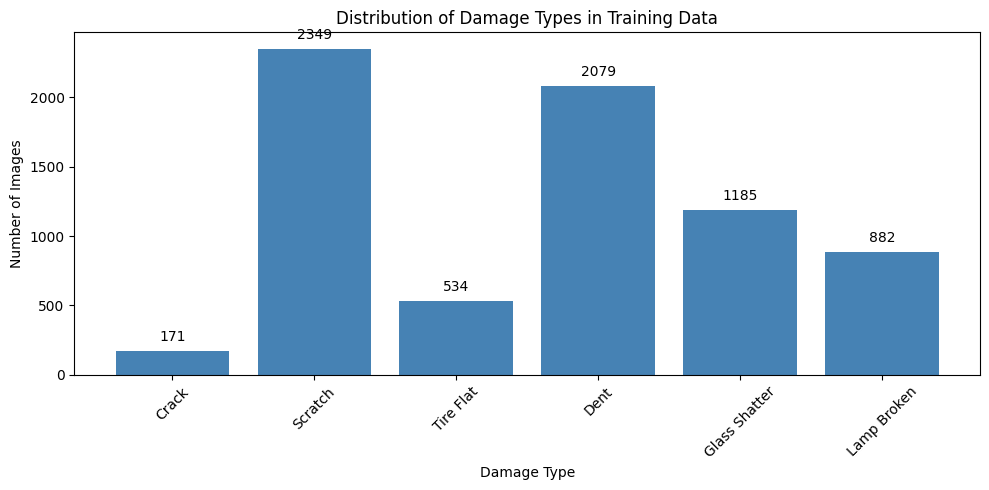

In [72]:
# Plot label distribution
plt.figure(figsize=(10, 5))
counts = train_df['label'].value_counts().sort_index()
labels = [class_names[i] for i in counts.index]
bars = plt.bar(labels, counts.values, color='steelblue')

plt.xlabel('Damage Type')
plt.ylabel('Number of Images')
plt.title('Distribution of Damage Types in Training Data')
plt.xticks(rotation=45)

for bar, val in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             str(val), ha='center', va='bottom')

plt.tight_layout()
plt.savefig('label_distribution.png')
plt.show()

In [73]:
# Add full filepath to each image
train_df['filepath'] = train_df['filename'].apply(lambda x: os.path.join(img_path, x))

# Convert labels to strings for ImageDataGenerator
train_df['label_str'] = train_df['label'].astype(str)

# Split into training and validation sets (80-20 split)
train_data, val_data = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    stratify=train_df['label']
)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))

Training samples: 5760
Validation samples: 1440


In [74]:
## Data Preprocessing and Augmentation

In [75]:
# Image parameters
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32

# Training data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation data generator (only rescaling, no augmentation)
val_datagen = ImageDataGenerator(rescale=1./255)

# Create generators from dataframe
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_data,
    x_col='filepath',
    y_col='label_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_data,
    x_col='filepath',
    y_col='label_str',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = 6
print("\nNumber of classes:", num_classes)
print("Image size:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Batch size:", BATCH_SIZE)

Found 5760 validated image filenames belonging to 6 classes.
Found 1440 validated image filenames belonging to 6 classes.

Number of classes: 6
Image size: 150 x 150
Batch size: 32


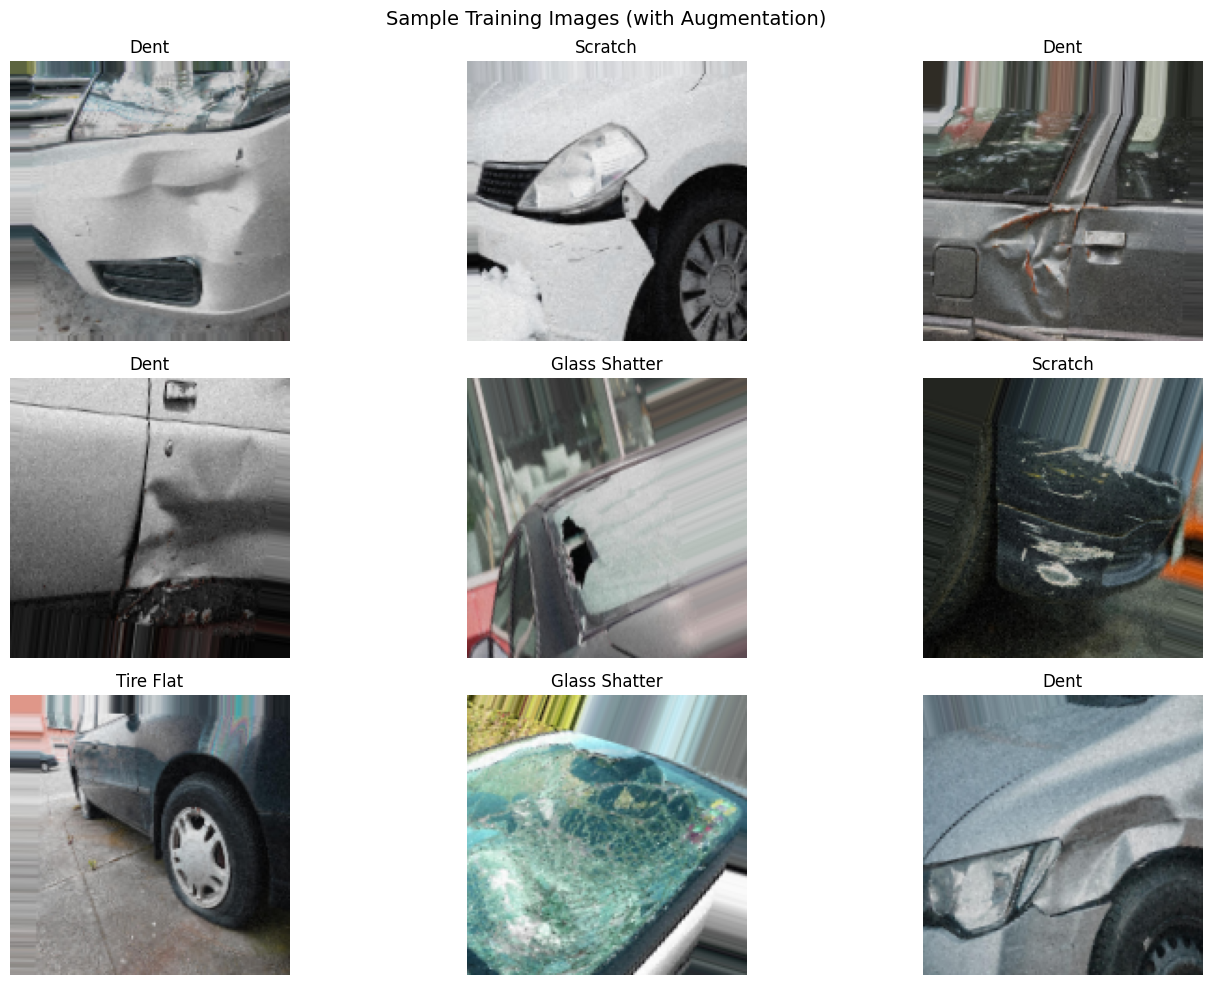

In [76]:
# Display sample images from training set
plt.figure(figsize=(15, 10))

images, labels = next(train_generator)

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    label_idx = np.argmax(labels[i]) + 1
    plt.title(class_names[label_idx])
    plt.axis('off')

plt.suptitle('Sample Training Images (with Augmentation)', fontsize=14)
plt.tight_layout()
plt.savefig('sample_images.png')
plt.show()

# Reset generator after sampling
train_generator.reset()

In [77]:
## CNN Model Architecture

In [78]:
# Build the CNN model
model = Sequential()

# First Convolutional Block (32 filters, 3x3 kernel)
model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu',
                 input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(BatchNormalization())

# Second Convolutional Block (64 filters, 3x3 kernel)
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(BatchNormalization())

# Third Convolutional Block (128 filters, 3x3 kernel)
model.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(BatchNormalization())

# Flatten layer
model.add(Flatten())

# Dense layer with 64 neurons
model.add(Dense(64, activation='relu'))

# Dropout layer with 50% rate
model.add(Dropout(0.5))

# Output layer with 6 neurons for 6 damage classes
model.add(Dense(num_classes, activation='softmax'))

# Display model summary
print("="*60)
print("CNN MODEL ARCHITECTURE")
print("="*60)
model.summary()

CNN MODEL ARCHITECTURE


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 74, 74, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 36, 36, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 17, 17, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     2,367,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,462,086 (9.39 MB)

 Trainable params: 2,461,638 (9.39 MB)

 Non-trainable params: 448 (1.75 KB)

In [79]:
# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")
print("Optimizer: Adam (learning_rate=0.01)")
print("Loss function: Categorical Crossentropy")
print("Metrics: Accuracy")

Model compiled successfully.
Optimizer: Adam (learning_rate=0.01)
Loss function: Categorical Crossentropy
Metrics: Accuracy


In [80]:
# Early stopping callback to prevent overfitting
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

print("Callbacks defined:")
print("- EarlyStopping: monitors val_loss, patience=10, restores best weights")

Callbacks defined:
- EarlyStopping: monitors val_loss, patience=10, restores best weights


In [81]:
## Model Training


In [82]:
# Train the model
EPOCHS = 30

print("="*60)
print("TRAINING THE CNN MODEL")
print("="*60)

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining completed.")
print("Training stopped at epoch:", len(history.history['loss']))

TRAINING THE CNN MODEL
Epoch 1/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 2710s 15s/step - accuracy: 0.2882 - loss: 36.8870 - val_accuracy: 0.3319 - val_loss: 1.5717
Epoch 2/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 466s 3s/step - accuracy: 0.3389 - loss: 1.5539 - val_accuracy: 0.3264 - val_loss: 1.5598
Epoch 3/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 460s 2s/step - accuracy: 0.3311 - loss: 1.5639 - val_accuracy: 0.3236 - val_loss: 1.5587
Epoch 4/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 422s 2s/step - accuracy: 0.3169 - loss: 1.5698 - val_accuracy: 0.3271 - val_loss: 1.5592
Epoch 5/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 424s 2s/step - accuracy: 0.3365 - loss: 1.5604 - val_accuracy: 0.3264 - val_loss: 1.5594
Epoch 6/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 431s 2s/step - accuracy: 0.3220 - loss: 1.5668 - val_accuracy: 0.3264 - val_loss: 1.5593
Epoch 7/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 440s 2s/step - accuracy: 0.3355 - loss: 1.5514 - val_accuracy: 0.3264 - val_loss: 1.5596
Epoch 8/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 437s 2s/step - accuracy: 0.3362

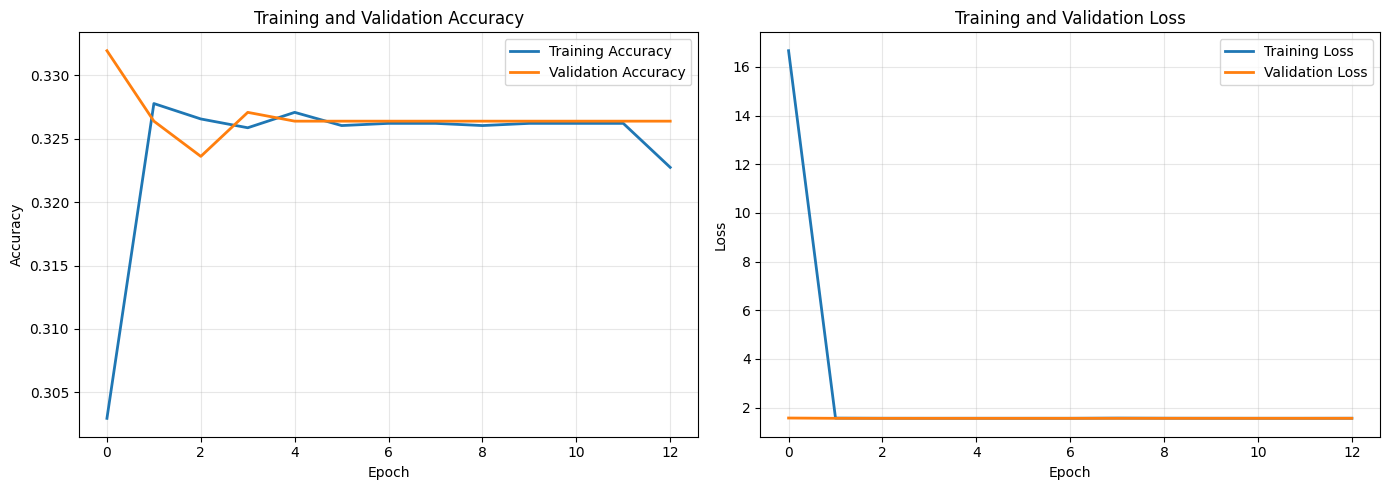

In [83]:
# Plot training and validation accuracy/loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Training and Validation Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss plot
axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Training and Validation Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cnn_training_history.png')
plt.show()

In [84]:
# Detailed overfitting analysis
print("="*60)
print("OVERFITTING ANALYSIS")
print("="*60)

final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]

acc_gap = final_train_acc - final_val_acc
loss_gap = final_val_loss - final_train_loss

print(f"\nFinal Training Accuracy: {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Accuracy Gap (Train - Val): {acc_gap:.4f}")

print(f"\nFinal Training Loss: {final_train_loss:.4f}")
print(f"Final Validation Loss: {final_val_loss:.4f}")
print(f"Loss Gap (Val - Train): {loss_gap:.4f}")

print("\nOVERFITTING ASSESSMENT:")
if acc_gap > 0.15:
    print("- SIGNIFICANT overfitting detected (accuracy gap > 0.15)")
    print("- Training accuracy much higher than validation accuracy")
    print("- Model may be memorising training data rather than generalising")
elif acc_gap > 0.05:
    print("- MILD overfitting detected (accuracy gap 0.05-0.15)")
    print("- Regularisation methods (Dropout, BatchNorm) are helping control it")
    print("- Early stopping prevented severe overfitting")
else:
    print("- NO significant overfitting detected (accuracy gap < 0.05)")
    print("- Model generalises well to unseen validation data")
    print("- Regularisation methods are working effectively")

print("\nEVIDENCE FROM TRAINING HISTORY PLOT:")
print("- If training and validation curves diverge significantly, this indicates overfitting")
print("- Training stopped at epoch", len(history.history['loss']), "due to early stopping")

OVERFITTING ANALYSIS

Final Training Accuracy: 0.3227
Final Validation Accuracy: 0.3264
Accuracy Gap (Train - Val): -0.0036

Final Training Loss: 1.5627
Final Validation Loss: 1.5605
Loss Gap (Val - Train): -0.0022

OVERFITTING ASSESSMENT:
- NO significant overfitting detected (accuracy gap < 0.05)
- Model generalises well to unseen validation data
- Regularisation methods are working effectively

EVIDENCE FROM TRAINING HISTORY PLOT:
- If training and validation curves diverge significantly, this indicates overfitting
- Training stopped at epoch 13 due to early stopping


In [85]:
## Model Evaluation


In [86]:
# Evaluate on validation set
print("="*60)
print("MODEL EVALUATION ON VALIDATION SET")
print("="*60)

val_loss, val_accuracy = model.evaluate(val_generator, verbose=1)

print(f"\nValidation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

MODEL EVALUATION ON VALIDATION SET
45/45 ━━━━━━━━━━━━━━━━━━━━ 35s 766ms/step - accuracy: 0.3360 - loss: 1.5521

Validation Loss: 1.5587
Validation Accuracy: 0.3236


In [87]:
# Get predictions on validation set
val_generator.reset()
predictions = model.predict(val_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = val_generator.classes

print("Predictions generated successfully.")
print("Number of predictions:", len(predicted_classes))

45/45 ━━━━━━━━━━━━━━━━━━━━ 36s 785ms/step
Predictions generated successfully.
Number of predictions: 1440


<Figure size 1000x800 with 0 Axes>

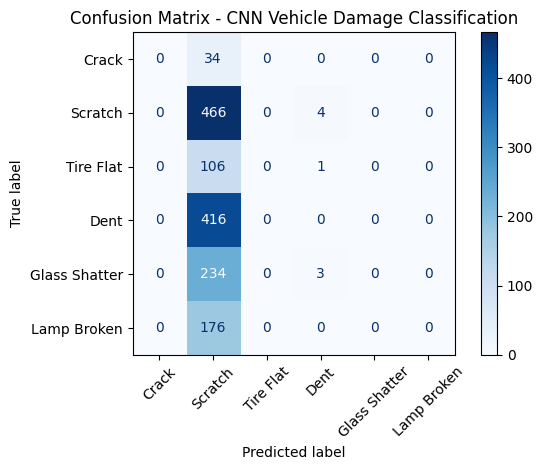

In [88]:
# Create and plot confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Get class labels for display
class_labels = [class_names[i+1] for i in range(6)]

plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix - CNN Vehicle Damage Classification')
plt.tight_layout()
plt.savefig('cnn_confusion_matrix.png')
plt.show()

In [89]:
# Print classification report
print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

CLASSIFICATION REPORT
               precision    recall  f1-score   support

        Crack       0.00      0.00      0.00        34
      Scratch       0.33      0.99      0.49       470
    Tire Flat       0.00      0.00      0.00       107
         Dent       0.00      0.00      0.00       416
Glass Shatter       0.00      0.00      0.00       237
  Lamp Broken       0.00      0.00      0.00       176

     accuracy                           0.32      1440
    macro avg       0.05      0.17      0.08      1440
 weighted avg       0.11      0.32      0.16      1440



## Hyperparameter Tuning


In [91]:
# Test different learning rates
learning_rates = [0.01, 0.001]
lr_results = []

print("="*60)
print("HYPERPARAMETER TUNING - LEARNING RATE")
print("="*60)

for lr in learning_rates:
    print(f"\nTesting learning rate: {lr}")

    # Build model
    model_lr = Sequential()
    model_lr.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu',
                        input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model_lr.add(MaxPooling2D(pool_size=(2, 2)))
    model_lr.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model_lr.add(MaxPooling2D(pool_size=(2, 2)))
    model_lr.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
    model_lr.add(MaxPooling2D(pool_size=(2, 2)))
    model_lr.add(Flatten())
    model_lr.add(Dense(64, activation='relu'))
    model_lr.add(Dropout(0.5))
    model_lr.add(Dense(num_classes, activation='softmax'))

    model_lr.compile(
        optimizer=Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    # Reset generators
    train_generator.reset()
    val_generator.reset()

    # Train for 5 epochs for comparison
    history_lr = model_lr.fit(
        train_generator,
        epochs=5,
        validation_data=val_generator,
        verbose=0
    )

    best_val_acc = max(history_lr.history['val_accuracy'])
    lr_results.append({
        'Learning_Rate': lr,
        'Best_Val_Accuracy': round(best_val_acc, 4)
    })
    print(f"  Best Validation Accuracy: {best_val_acc:.4f}")

lr_results_df = pd.DataFrame(lr_results)
print("\n" + "="*60)
print("LEARNING RATE COMPARISON")
print("="*60)
print(lr_results_df.to_string(index=False))

best_lr = lr_results_df.loc[lr_results_df['Best_Val_Accuracy'].idxmax(), 'Learning_Rate']
print(f"\nBest learning rate: {best_lr}")

HYPERPARAMETER TUNING - LEARNING RATE

Testing learning rate: 0.01
  Best Validation Accuracy: 0.3264

Testing learning rate: 0.001
  Best Validation Accuracy: 0.5104

LEARNING RATE COMPARISON
 Learning_Rate  Best_Val_Accuracy
         0.010             0.3264
         0.001             0.5104

Best learning rate: 0.001


In [92]:
# Test different batch sizes
batch_sizes = [32, 128]
batch_results = []

print("="*60)
print("HYPERPARAMETER TUNING - BATCH SIZE")
print("="*60)

for bs in batch_sizes:
    print(f"\nTesting batch size: {bs}")

    # Create generators with new batch size
    train_gen_bs = train_datagen.flow_from_dataframe(
        dataframe=train_data,
        x_col='filepath',
        y_col='label_str',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=bs,
        class_mode='categorical',
        shuffle=True
    )

    val_gen_bs = val_datagen.flow_from_dataframe(
        dataframe=val_data,
        x_col='filepath',
        y_col='label_str',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=bs,
        class_mode='categorical',
        shuffle=False
    )

    # Build model
    model_bs = Sequential()
    model_bs.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu',
                        input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model_bs.add(MaxPooling2D(pool_size=(2, 2)))
    model_bs.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model_bs.add(MaxPooling2D(pool_size=(2, 2)))
    model_bs.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
    model_bs.add(MaxPooling2D(pool_size=(2, 2)))
    model_bs.add(Flatten())
    model_bs.add(Dense(64, activation='relu'))
    model_bs.add(Dropout(0.5))
    model_bs.add(Dense(num_classes, activation='softmax'))

    model_bs.compile(
        optimizer=Adam(learning_rate=0.01),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history_bs = model_bs.fit(
        train_gen_bs,
        epochs=5,
        validation_data=val_gen_bs,
        verbose=0
    )

    best_val_acc = max(history_bs.history['val_accuracy'])
    batch_results.append({
        'Batch_Size': bs,
        'Best_Val_Accuracy': round(best_val_acc, 4)
    })
    print(f"  Best Validation Accuracy: {best_val_acc:.4f}")

batch_results_df = pd.DataFrame(batch_results)
print("\n" + "="*60)
print("BATCH SIZE COMPARISON")
print("="*60)
print(batch_results_df.to_string(index=False))

best_bs = batch_results_df.loc[batch_results_df['Best_Val_Accuracy'].idxmax(), 'Batch_Size']
print(f"\nBest batch size: {best_bs}")

HYPERPARAMETER TUNING - BATCH SIZE

Testing batch size: 32
Found 5760 validated image filenames belonging to 6 classes.
Found 1440 validated image filenames belonging to 6 classes.
  Best Validation Accuracy: 0.3264

Testing batch size: 128
Found 5760 validated image filenames belonging to 6 classes.
Found 1440 validated image filenames belonging to 6 classes.
  Best Validation Accuracy: 0.3264

BATCH SIZE COMPARISON
 Batch_Size  Best_Val_Accuracy
         32             0.3264
        128             0.3264

Best batch size: 32


In [93]:
# Test different dropout rates
dropout_rates = [0.25, 0.5, 0.75]
dropout_results = []

print("="*60)
print("HYPERPARAMETER TUNING - DROPOUT RATE")
print("="*60)

for drop in dropout_rates:
    print(f"\nTesting dropout rate: {drop}")

    model_drop = Sequential()
    model_drop.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu',
                          input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model_drop.add(MaxPooling2D(pool_size=(2, 2)))
    model_drop.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model_drop.add(MaxPooling2D(pool_size=(2, 2)))
    model_drop.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
    model_drop.add(MaxPooling2D(pool_size=(2, 2)))
    model_drop.add(Flatten())
    model_drop.add(Dense(64, activation='relu'))
    model_drop.add(Dropout(drop))
    model_drop.add(Dense(num_classes, activation='softmax'))

    model_drop.compile(
        optimizer=Adam(learning_rate=0.01),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    train_generator.reset()
    val_generator.reset()

    history_drop = model_drop.fit(
        train_generator,
        epochs=5,
        validation_data=val_generator,
        verbose=0
    )

    best_val_acc = max(history_drop.history['val_accuracy'])
    dropout_results.append({
        'Dropout_Rate': drop,
        'Best_Val_Accuracy': round(best_val_acc, 4)
    })
    print(f"  Best Validation Accuracy: {best_val_acc:.4f}")

dropout_results_df = pd.DataFrame(dropout_results)
print("\n" + "="*60)
print("DROPOUT RATE COMPARISON")
print("="*60)
print(dropout_results_df.to_string(index=False))

best_drop = dropout_results_df.loc[dropout_results_df['Best_Val_Accuracy'].idxmax(), 'Dropout_Rate']
print(f"\nBest dropout rate: {best_drop}")

HYPERPARAMETER TUNING - DROPOUT RATE

Testing dropout rate: 0.25
  Best Validation Accuracy: 0.3264

Testing dropout rate: 0.5
  Best Validation Accuracy: 0.3264

Testing dropout rate: 0.75
  Best Validation Accuracy: 0.3264

DROPOUT RATE COMPARISON
 Dropout_Rate  Best_Val_Accuracy
         0.25             0.3264
         0.50             0.3264
         0.75             0.3264

Best dropout rate: 0.25


In [94]:
# Summary of hyperparameter tuning results
print("="*60)
print("HYPERPARAMETER TUNING SUMMARY")
print("="*60)

print("\nLearning Rate Results:")
print(lr_results_df.to_string(index=False))

print("\nBatch Size Results:")
print(batch_results_df.to_string(index=False))

print("\nDropout Rate Results:")
print(dropout_results_df.to_string(index=False))

print("\n" + "-"*60)
print("OPTIMAL HYPERPARAMETERS:")
print("-"*60)
print(f"Learning Rate: {best_lr}")
print(f"Batch Size: {best_bs}")
print(f"Dropout Rate: {best_drop}")

HYPERPARAMETER TUNING SUMMARY

Learning Rate Results:
 Learning_Rate  Best_Val_Accuracy
         0.010             0.3264
         0.001             0.5104

Batch Size Results:
 Batch_Size  Best_Val_Accuracy
         32             0.3264
        128             0.3264

Dropout Rate Results:
 Dropout_Rate  Best_Val_Accuracy
         0.25             0.3264
         0.50             0.3264
         0.75             0.3264

------------------------------------------------------------
OPTIMAL HYPERPARAMETERS:
------------------------------------------------------------
Learning Rate: 0.001
Batch Size: 32
Dropout Rate: 0.25
